# Raio-X do Mercado de Trabalho Industrial de SC
**Equipe Kirasapiens Neurotech — Datathon UniSENAI 2026**

> *Quais regiões e setores industriais de SC enfrentam apagão de mão de obra ou expansão acelerada, e como renda e escolaridade explicam esses gargalos?*

Este notebook documenta o pipeline completo: carga, limpeza, junção com dados municipais e regiões do IBGE,
agrupamento de CBOs por IA em macrofamílias, cálculo dos indicadores e diagnóstico.
O código reutilizável está em `backend/` e o dashboard em `dashboard/app.py`.

In [1]:
import sys; sys.path.insert(0, '../backend')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import pipeline
from indicadores import tabela, classificar
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)

## 1. Carga e limpeza
Roda o pipeline de ponta a ponta (gera `data/processed/`). A tabela abaixo é a volumetria de cada etapa.

In [2]:
pipeline.main()
pd.read_csv('../data/processed/log_limpeza.csv')

Carga inicial (todas as seções)                          3,397,416


Competência dentro da janela (202509, 202608)            3,391,288


Remove categoria/tipo de movimentação não identificados  3,390,779


Indústria de transformação (seção C)                       835,776
 ...das quais com salário válido p/ comparações            781,353



Diagnóstico região x setor:
diagnostico
Volume insuficiente      218
Estável                  197
Retração                  32
Expansão acelerada        30
Apagão de mão de obra     20
Expansão sob pressão       6


,etapa,linhas
0,Carga inicial (todas as seções),3397416
1,"Competência dentro da janela (202509, 202608)",3391288
2,Remove categoria/tipo de movimentação não iden...,3390779
3,Indústria de transformação (seção C),835776
4,...das quais com salário válido p/ comparações,781353


**Decisões de limpeza**
- Janela de 12 competências (set/2025 a ago/2026); declarações fora do prazo com competência anterior saem.
- Removidas categorias e tipos de movimentação não identificados.
- Salário só entra nas comparações se estiver entre R$ 800 e R$ 60 mil, com jornada ≥ 30h e sem intermitente, aprendiz ou parcial.
- O arquivo fornecido é apenas a base **MOV**; a base de exclusões (EXC) não foi disponibilizada, então não há desconto de exclusões.

## 2. Base da indústria enriquecida

In [3]:
ind = pd.read_parquet('../data/processed/industria.parquet')
print(f'{len(ind):,} movimentações na indústria de transformação')
ind.head()

835,776 movimentações na indústria de transformação


,competênciamov,cod_ibge,municipio_nome,regiao_imediata,regiao_intermediaria,divisao_cnae,setor,cbo,macrofamilia,nivel_ocupacao,admissao,pedido,tipomovimentação,salario,salario_valido,graudeinstrução,idade,sexo,tamestabjan
0,202509,4215554,Santa Helena,São Miguel do Oeste,Chapecó,25,Produtos de metal,253405,"Administrativo, Comercial e Negócios",Nível superior,False,True,40,1650.00,True,8,34.0,3,4
1,202509,4219309,Videira,Videira,Caçador,10,Alimentos,848520,Agroindústria e Alimentos,Operacional,True,False,97,1929.40,True,3,18.0,1,10
2,202509,4214805,Rio do Sul,Rio do Sul,Blumenau,29,Veículos automotores,722315,Metalmecânica e Montagem,Operacional,False,True,40,2759.64,True,7,39.0,1,9
3,202509,4202404,Blumenau,Blumenau,Blumenau,13,Têxtil,761435,"Têxtil, Vestuário, Couro e Calçados",Operacional,True,False,97,2528.56,True,5,58.0,3,7
4,202509,4213203,Pomerode,Blumenau,Blumenau,25,Produtos de metal,121005,Gestão e Liderança,Gestão,False,False,31,4508.67,False,7,34.0,3,5


In [4]:
saldo = lambda s: 2*s.sum() - len(s)
print('Saldo total da indústria:', saldo(ind['admissao']))
ind.groupby('regiao_intermediaria', observed=True)['admissao'].agg(movimentacoes='size', saldo=saldo).sort_values('saldo')

Saldo total da indústria: 1098


,movimentacoes,saldo
regiao_intermediaria,,
Criciúma,117553,-937
Florianópolis,40729,-777
Blumenau,278218,-576
Joinville,189202,-504
Caçador,36124,-80
Lages,23966,224
Chapecó,149984,3748


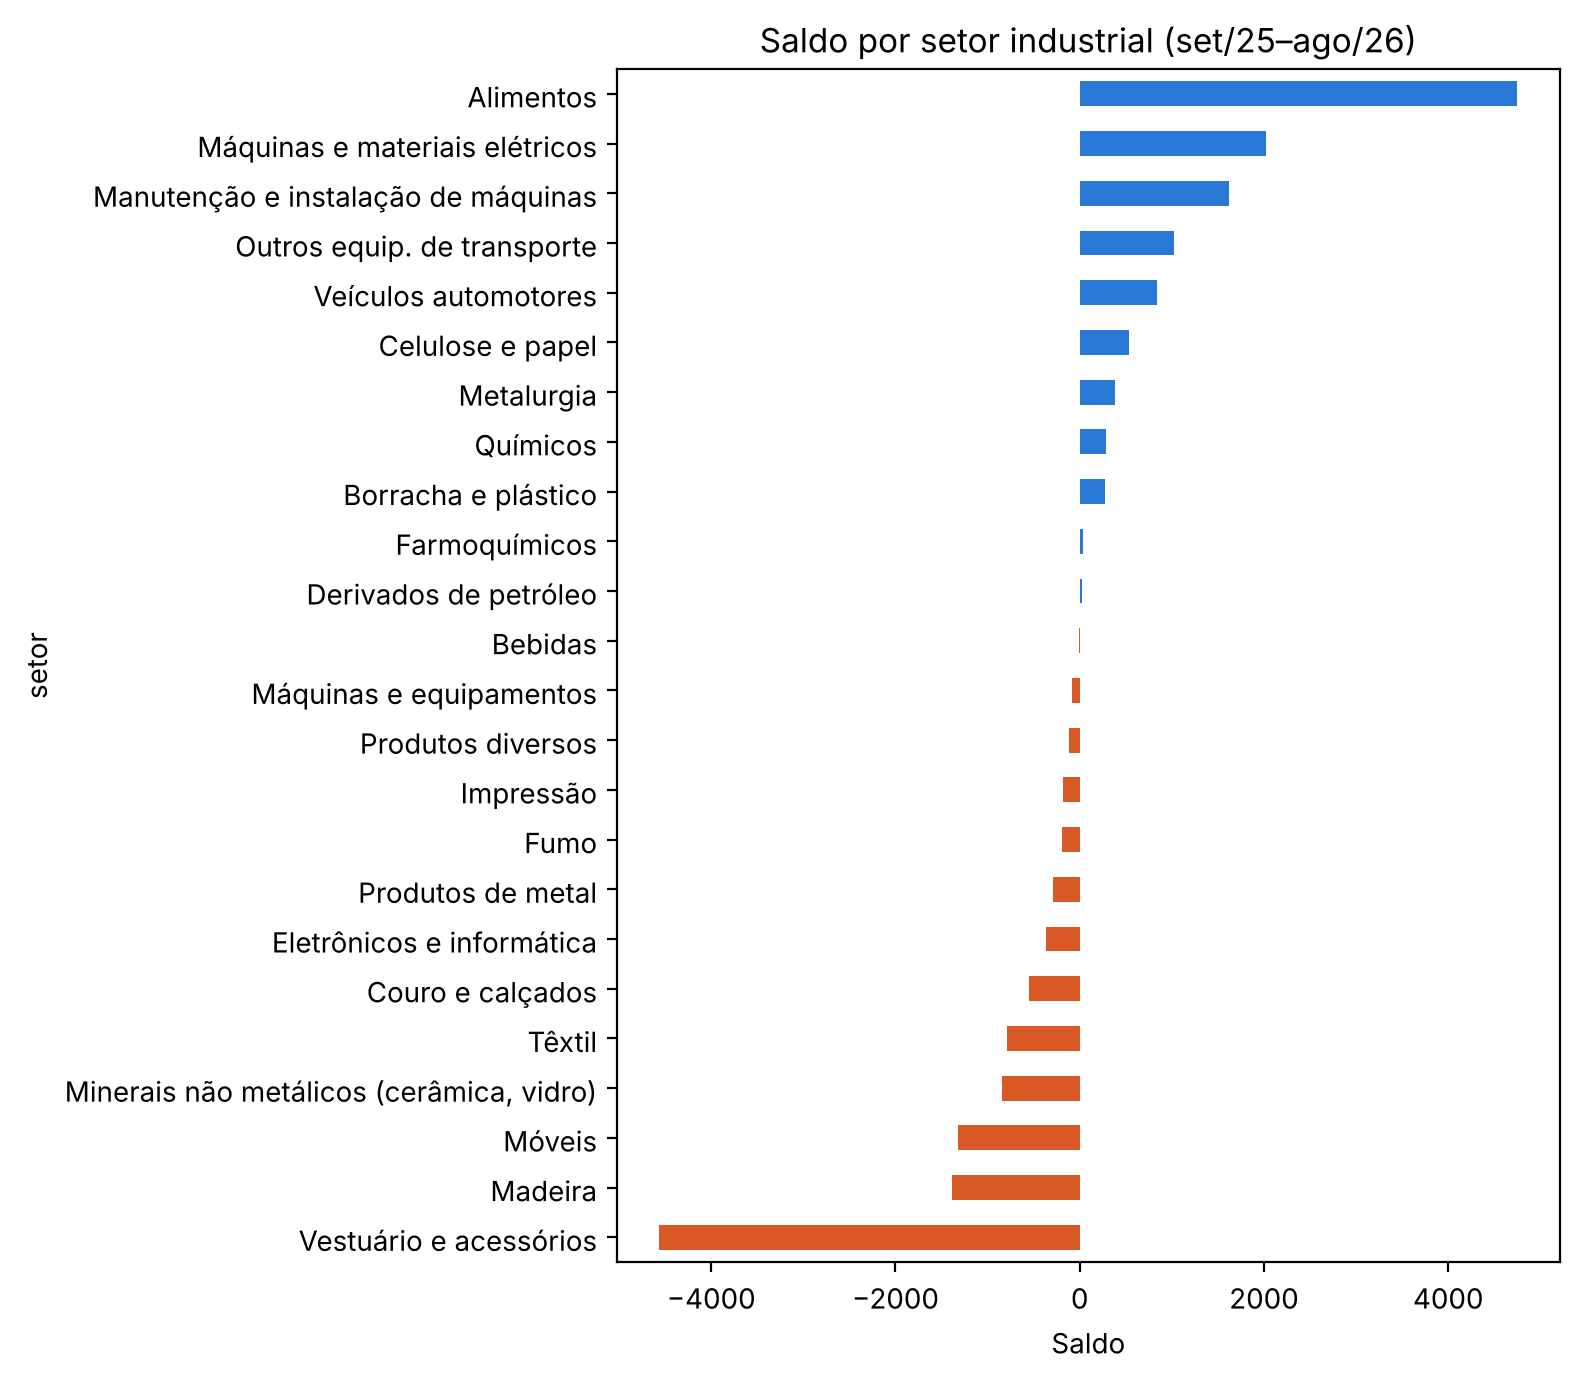

In [5]:
s = ind.groupby('setor', observed=True)['admissao'].agg(movimentacoes='size', saldo=saldo).sort_values('saldo')
ax = s['saldo'].plot.barh(figsize=(8,7), color=np.where(s['saldo']>=0,'#2a78d6','#d95926'))
ax.set_title('Saldo por setor industrial (set/25–ago/26)'); ax.set_xlabel('Saldo'); plt.tight_layout()

## 3. Macrofamílias de CBO com IA generativa
Os 1.467 CBOs da indústria pertencem a 177 subgrupos (3 dígitos). Para cada subgrupo enviamos ao LLM os títulos
das ocupações mais frequentes e pedimos a classificação em 16 macrofamílias fechadas (prompt em `backend/cbo_llm.py`).
O resultado, revisado pela equipe, está em `data/cbo_macrofamilias.csv`.

In [6]:
import cbo_llm
print(cbo_llm.PROMPT[:600], '...')
mf_map = pd.read_csv('../data/cbo_macrofamilias.csv')
mf_map.groupby('macrofamilia').size().sort_values(ascending=False)

Você é especialista na Classificação Brasileira de Ocupações (CBO 2002)
e no parque industrial de Santa Catarina.

Classifique cada subgrupo de CBO abaixo em EXATAMENTE UMA das macrofamílias:
{familias}

Regras:
- Use os títulos de ocupação como evidência principal.
- Mestres, encarregados e supervisores de produção vão para
  "Supervisão de Produção (Mestres e Encarregados)".
- Ocupações de nível superior em engenharia, TI, química e design de produto
  vão para "Engenharia, TI e P&D".
- Responda SOMENTE com JSON no formato {{"<subgrupo>": "<macrofamília>", ...}}.

Subgrupos:
{subgrupos}
 ...


macrofamilia
Administrativo, Comercial e Negócios               36
Técnicos Industriais e Qualidade                   18
Supervisão de Produção (Mestres e Encarregados)    15
Gestão e Liderança                                 13
Processos Químicos, Plásticos, Papel e Cerâmica    13
Engenharia, TI e P&D                               12
Metalmecânica e Montagem                           11
Agropecuária, Pesca e Florestal                    10
Serviços de Apoio                                  10
Manutenção Industrial                               9
Têxtil, Vestuário, Couro e Calçados                 8
Madeira e Móveis                                    7
Construção e Extração Mineral                       5
Logística e Movimentação                            4
Agroindústria e Alimentos                           3
Produção de Base (Linha e Embalagem)                2
Não identificado                                    1
dtype: int64

## 4. Indicadores
| Indicador | Definição | Leitura |
|---|---|---|
| Saldo por 10 mil hab. | (admissões − desligamentos) ÷ população 2026 × 10.000 | expansão |
| % desligamentos a pedido | desligamentos tipo 40 ÷ desligamentos | trabalhador sai porque tem opção |
| Índice de reposição | desligamentos ÷ admissões | perto de 1 = contrata só para repor |
| Prêmio salarial ajustado | média ponderada, por CBO, de log(mediana adm ÷ mediana desl) | empresa paga mais para repor |
| **Índice de pressão (apagão)** | média dos z-scores dos três acima | > 0,5 = alerta |
| **Índice de expansão** | z-score do saldo por 10 mil hab. | > 0,5 = expansão acelerada |

In [7]:
mf = pd.read_csv('../data/processed/ind_macrofamilia.csv').sort_values('indice_pressao', ascending=False)
mf[['macrofamilia','admissoes','saldo','pct_pedido_demissao','indice_reposicao','salario_mediano_adm',
    'pct_superior_adm','indice_pressao','diagnostico']].round(3)

,macrofamilia,admissoes,saldo,pct_pedido_demissao,indice_reposicao,salario_mediano_adm,pct_superior_adm,indice_pressao,diagnostico
10,Não identificado,50.0,49.0,1.000,0.020,2316.95,0.080,1.120,Volume insuficiente
1,Agroindústria e Alimentos,29487.0,2078.0,0.603,0.930,2146.01,0.013,0.665,Expansão sob pressão
16,"Têxtil, Vestuário, Couro e Calçados",57570.0,-3634.0,0.556,1.063,2120.00,0.015,0.452,Estável
12,Produção de Base (Linha e Embalagem),115939.0,15527.0,0.560,0.866,2100.00,0.015,0.401,Expansão acelerada
7,Madeira e Móveis,10001.0,-2081.0,0.504,1.208,2200.00,0.011,0.332,Retração
13,Serviços de Apoio,16116.0,625.0,0.503,0.961,2100.00,0.027,0.238,Estável
11,"Processos Químicos, Plásticos, Papel e Cerâmica",22604.0,-3744.0,0.507,1.166,2224.20,0.024,0.197,Estável
6,Logística e Movimentação,35763.0,-642.0,0.476,1.018,2300.00,0.032,0.080,Estável
2,"Agropecuária, Pesca e Florestal",3016.0,1268.0,0.504,0.580,2300.00,0.010,0.025,Expansão acelerada
9,Metalmecânica e Montagem,44952.0,-1265.0,0.465,1.028,2500.00,0.020,-0.068,Estável


## 5. Diagnóstico região imediata × setor

In [8]:
rs = pd.read_csv('../data/processed/ind_regiao_setor.csv')
rs = rs[rs['movimentacoes'] >= 300]
print(rs['diagnostico'].value_counts())
cols = ['regiao_imediata','setor','movimentacoes','saldo','saldo_10k_hab','pct_pedido_demissao',
        'indice_reposicao','salario_mediano_adm','indice_pressao','indice_expansao','diagnostico']
rs[rs['diagnostico'].isin(['Apagão de mão de obra','Expansão sob pressão'])].sort_values('movimentacoes', ascending=False)[cols].round(2)

diagnostico
Estável                  197
Retração                  32
Expansão acelerada        30
Apagão de mão de obra     20
Expansão sob pressão       6
Name: count, dtype: int64


,regiao_imediata,setor,movimentacoes,saldo,saldo_10k_hab,pct_pedido_demissao,indice_reposicao,salario_mediano_adm,indice_pressao,indice_expansao,diagnostico
251,Joaçaba - Herval d'Oeste,Alimentos,12233.0,463.0,24.22,0.68,0.93,2035.00,0.71,3.01,Expansão sob pressão
417,São Miguel do Oeste,Alimentos,9910.0,198.0,11.03,0.72,0.96,2088.40,0.58,1.36,Expansão sob pressão
208,Ibirama - Presidente Getúlio,Vestuário e acessórios,6596.0,-32.0,-4.96,0.72,1.01,1936.00,0.77,-0.63,Apagão de mão de obra
102,Chapecó,Móveis,5358.0,36.0,0.71,0.64,0.99,2061.00,0.56,0.08,Apagão de mão de obra
315,Mafra,Alimentos,3892.0,150.0,6.16,0.62,0.93,2043.59,0.62,0.76,Expansão sob pressão
220,Itajaí,Manutenção e instalação de máquinas,3826.0,516.0,5.04,0.43,0.76,2800.00,1.01,0.62,Expansão sob pressão
398,São Bento do Sul - Rio Negrinho,Veículos automotores,3671.0,-83.0,-5.87,0.63,1.05,2000.00,0.57,-0.74,Apagão de mão de obra
459,Tubarão,Veículos automotores,2398.0,-20.0,-0.57,0.68,1.02,2413.43,0.76,-0.08,Apagão de mão de obra
117,Concórdia,Madeira,1636.0,120.0,7.46,0.63,0.86,2220.00,0.54,0.92,Expansão sob pressão
72,Caçador,Couro e calçados,1294.0,-22.0,-2.12,0.70,1.03,1909.60,0.56,-0.27,Apagão de mão de obra


In [9]:
rs[rs['diagnostico']=='Expansão acelerada'].sort_values('saldo', ascending=False)[cols].round(2).head(12)

,regiao_imediata,setor,movimentacoes,saldo,saldo_10k_hab,pct_pedido_demissao,indice_reposicao,salario_mediano_adm,indice_pressao,indice_expansao,diagnostico
88,Chapecó,Alimentos,32551.0,2407.0,47.73,0.55,0.86,2175.80,-0.01,5.93,Expansão acelerada
232,Itajaí,Veículos automotores,5394.0,1626.0,15.87,0.57,0.54,2079.00,0.22,1.97,Expansão acelerada
226,Itajaí,Outros equip. de transporte,5790.0,964.0,9.41,0.43,0.71,2881.28,-0.28,1.16,Expansão acelerada
286,Joinville,Máquinas e materiais elétricos,16142.0,898.0,7.63,0.56,0.89,2219.80,-0.10,0.94,Expansão acelerada
130,Criciúma,Alimentos,10431.0,617.0,12.80,0.54,0.89,2300.00,0.22,1.58,Expansão acelerada
37,Blumenau,Máquinas e materiais elétricos,5138.0,514.0,7.19,0.46,0.82,2327.60,-0.33,0.88,Expansão acelerada
66,Brusque,Têxtil,21570.0,398.0,15.36,0.42,0.96,2622.79,-0.50,1.90,Expansão acelerada
481,Xanxerê,Alimentos,6730.0,318.0,23.55,0.54,0.91,1977.69,0.20,2.92,Expansão acelerada
298,Lages,Celulose e papel,1658.0,294.0,9.60,0.42,0.70,2181.70,-0.31,1.18,Expansão acelerada
303,Lages,Manutenção e instalação de máquinas,1809.0,239.0,7.80,0.26,0.77,3520.00,-0.71,0.96,Expansão acelerada


## 6. Renda e escolaridade: o gargalo é diploma ou salário?

In [10]:
a = ind[ind['admissao']]
nivel = ind.groupby('nivel_ocupacao', observed=True)['admissao'].agg(movimentacoes='size', saldo=saldo)
nivel['salario_mediano_adm'] = a[a['salario_valido']].groupby('nivel_ocupacao', observed=True)['salario'].median()
nivel

,movimentacoes,saldo,salario_mediano_adm
nivel_ocupacao,,,
Gestão,8235,-1699,4009.08
Nível superior,11812,-800,4000.00
Operacional,770678,6326,2176.63
Técnico (nível médio),45051,-2729,2900.00


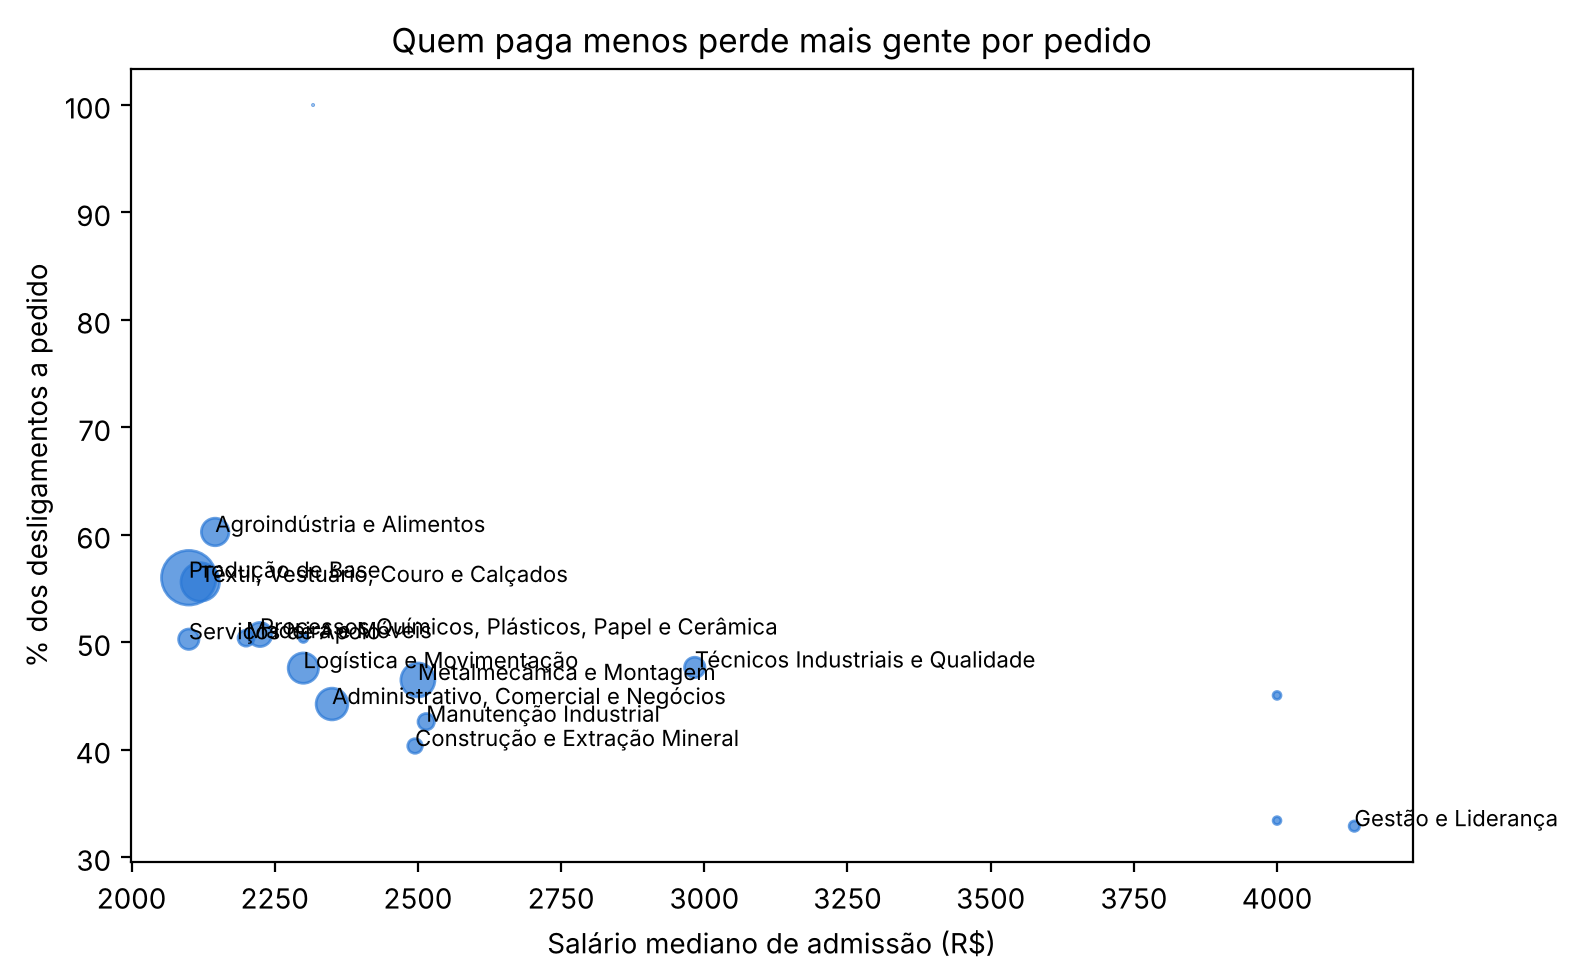

In [11]:
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(mf['salario_mediano_adm'], mf['pct_pedido_demissao']*100, s=mf['admissoes']/300, color='#2a78d6', alpha=.7)
for _, r in mf[mf['admissoes']>4000].iterrows():
    ax.annotate(r['macrofamilia'].split(' (')[0], (r['salario_mediano_adm'], r['pct_pedido_demissao']*100), fontsize=8)
ax.set_xlabel('Salário mediano de admissão (R$)'); ax.set_ylabel('% dos desligamentos a pedido')
ax.set_title('Quem paga menos perde mais gente por pedido'); plt.tight_layout()

## 7. Conclusões
1. **A indústria catarinense girou o quadro sem crescer:** 835 mil movimentações para um saldo de pouco mais de mil vagas em 12 meses.
2. **O crescimento é operacional e concentrado no Oeste (agroindústria) e em Itajaí:** técnicos, gestão e nível superior tiveram saldo negativo.
3. **O apagão é de retenção, não de diploma:** as famílias com mais saídas a pedido (agroindústria, produção de base, têxtil e vestuário)
   pagam cerca de R$ 2,0–2,2 mil na admissão e exigem pouca escolaridade.
4. **Limites:** CAGED mede fluxo, não estoque nem vagas abertas; sem base EXC; o prêmio salarial é naturalmente negativo
   (quem sai tem mais tempo de casa), por isso o índice compara setores entre si.